# Motion blur research: notebook

ICMTC research task, due Sat 21 Nov 2026. One notebook, one section per milestone.

| Milestone | Section | Status |
|---|---|---|
| M1 blur budget | (in the doc) | done |
| **M2 fake motion blur** | **this section** | in progress |
| M3 blur score | later | |
| M4 recall vs blur on VisDrone | later | |


## M2: Fake motion blur

**Where it fits:** M1 said how many pixels of blur to expect (N). M2 *creates* exactly N pixels of blur on any image, so M3 and M4 can test it.

**The idea (your bucket picture):** every output pixel = the average of N neighbours in a line. As a kernel that is one row of N values, each `1/N`. The weights sum to 1, so brightness is kept (blur moves light, it doesn't add any).

**How to run:** Run All. Each test cell checks the function above it and prints "passed".

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

IMG_PATH = "../../phase 1 of the season/datasets/coco8/images/val/000000000036.jpg"   # any photo works
img = cv.imread(IMG_PATH)
assert img is not None, "image not found, check IMG_PATH"
print("image shape:", img.shape)

image shape: (640, 481, 3)


### Function card 1: `make_motion_kernel(N)`

| | |
|---|---|
| **Input** | `N`: blur length in pixels (int, at least 1). This is the number from your M1 table |
| **Output** | a 2D float array of shape `(1, N)`: one row of N equal values that **sum to 1** |
| **Tools** | `np.ones(shape, dtype=np.float32)`, then divide |

**Plain-English skeleton**
1. Make a row of N ones (shape `(1, N)`, float32).
2. Divide it by N, so each value is `1/N`.
3. Return it.

Example: `N = 4` → `[[0.25, 0.25, 0.25, 0.25]]`

In [2]:
def make_motion_kernel(N):
    """One row of N equal weights (each 1/N) -> horizontal motion blur of N pixels."""
    kernel = np.ones((1, N), dtype=np.float32)   # a row of N ones
    return kernel / N                              # each weight 1/N, so they sum to 1 (brightness kept)

In [3]:
# Test 1 (ready, just run it)
k = make_motion_kernel(4)
print(k)
assert k.shape == (1, 4), f"shape should be (1, 4), got {k.shape}"
assert np.isclose(k.sum(), 1.0), f"weights should sum to 1, got {k.sum()}"
assert np.allclose(make_motion_kernel(1), [[1.0]]), "N=1 should be [[1.]] (no blur)"
print("Test 1 passed")

[[0.25 0.25 0.25 0.25]]
Test 1 passed


### Function card 2: `motion_blur(img, N)`

| | |
|---|---|
| **Input** | `img`: an image (BGR or gray); `N`: blur length in pixels |
| **Output** | the blurred image, same shape and dtype as `img` |
| **Tools** | your `make_motion_kernel(N)`, then `cv.filter2D(src, ddepth, kernel)` with `ddepth=-1` (keep the same dtype). Same call as the "To apply any kernel" cell in your Session 2 notebook |

**Plain-English skeleton**
1. Build the kernel with your function from card 1.
2. Slide it over the image with `filter2D`.
3. Return the result.

This blurs **horizontally** (the drone flying left to right in the image).

In [4]:
def motion_blur(img, N):
    """Blur img horizontally by N pixels, like a drone moving left-right during the exposure."""
    kernel = make_motion_kernel(N)
    return cv.filter2D(img, -1, kernel)   # slide the kernel over the image; -1 = keep the same dtype

non-zero pixels in the dot's row: 5 (should be 5)


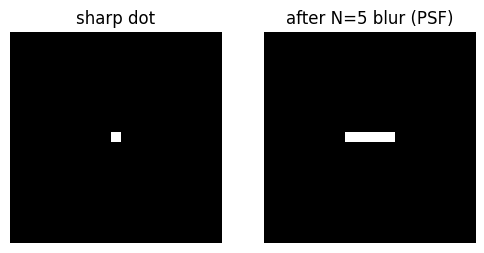

Test 2 passed


In [5]:
# Test 2 (ready, just run it)
# a) flat gray image: brightness must stay 100 (the sum-to-1 rule)
flat = np.full((50, 50), 100, np.uint8)
assert np.all(motion_blur(flat, 7)[:, 10:40] == 100), "flat area changed brightness: check the kernel sums to 1"

# b) one white dot -> should become a horizontal line of N pixels (the PSF)
dot = np.zeros((21, 21), np.uint8); dot[10, 10] = 255
psf = motion_blur(dot, 5)
print("non-zero pixels in the dot's row:", np.count_nonzero(psf[10]), "(should be 5)")
assert np.count_nonzero(psf) == 5 and np.count_nonzero(psf[10]) == 5

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(dot, cmap="gray"); ax[0].set_title("sharp dot")
ax[1].imshow(psf, cmap="gray"); ax[1].set_title("after N=5 blur (PSF)")
for a in ax: a.axis("off")
plt.show()
print("Test 2 passed")

### Demo: the same photo at the blur values from M1

N = 1 is the original. Look at edges that run **across** the motion (they smear) vs **along** it (they stay sharp).

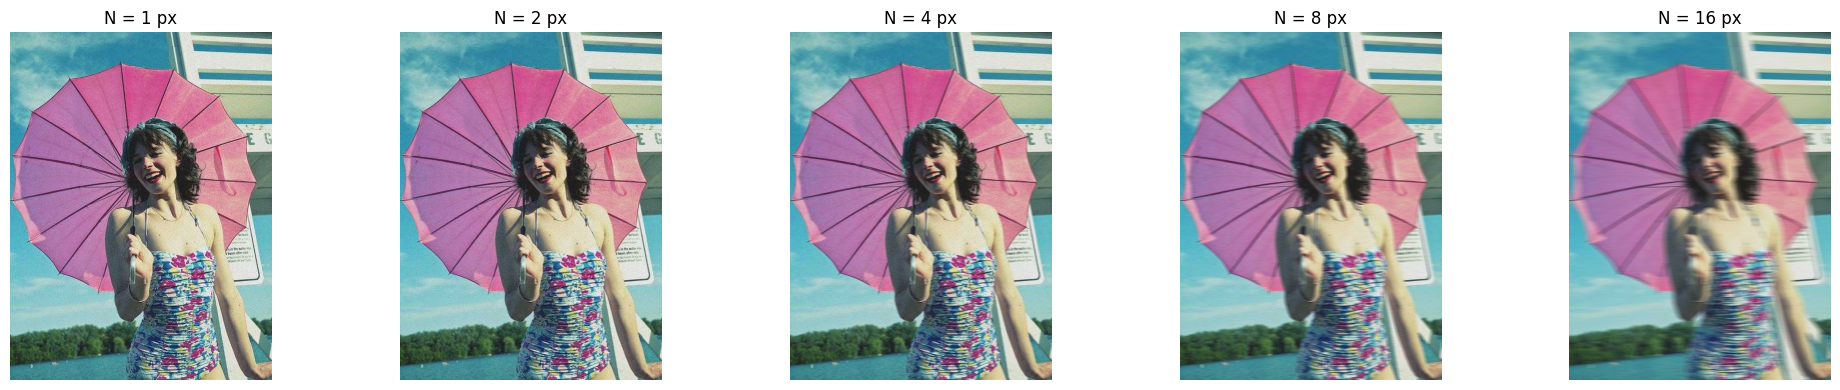

In [6]:
Ns = [1, 2, 4, 8, 16]
fig, axes = plt.subplots(1, len(Ns), figsize=(4 * len(Ns), 4))
for ax, N in zip(axes, Ns):
    ax.imshow(cv.cvtColor(motion_blur(img, N), cv.COLOR_BGR2RGB))
    ax.set_title(f"N = {N} px")
    ax.axis("off")
plt.tight_layout()
plt.show()

### M2 result ✅ done

- Test 1 and Test 2 pass.
- The demo shows more smear as N grows (edges across the motion smear, edges along it stay sharp).
- **Why the dot became a line (PSF):** during the exposure the dot's light slid across N pixels, so it was split into N equal parts (1/N each) along the motion. That line *is* the motion blur's point spread function, and it's the same shape as our kernel.

Next: **M3**, a number that measures how blurry an image is (Laplacian variance).

## M3: Blur score (Laplacian variance)

**Where it fits:** M2 *made* blur. M3 *measures* it automatically: one number per frame. Picking the sharpest frames is also one of the fixes we'll recommend.

**The idea:**
1. The Laplacian kernel `[0 1 0; 1 -4 1; 0 1 0]` (weights sum to 0) gives 0 on flat areas and big +/- spikes on sharp edges.
2. Sharp image → lots of big spikes → the values are spread out → **high variance**.
3. Blurred image → edges ramp slowly → small values → **low variance**.

So `variance of the Laplacian` = **sharpness score** (higher = sharper).

In [7]:
def blur_score(img):
    """Sharpness score: variance of the Laplacian. Higher = sharper."""
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY) if img.ndim == 3 else img   # edges live in brightness, colour not needed
    lap = cv.Laplacian(gray, cv.CV_64F)   # 2nd-derivative filter; CV_64F keeps the negative spikes (uint8 would cut them to 0)
    return lap.var()                      # spread of the edge responses = how sharp

### Test 3: does the score drop as blur grows?

Blur the same photo with the M2 function at N = 1, 2, 4, 8, 16 and score each one. The score must go **down** every time.

N =  1 px  ->  score =   4989.0
N =  2 px  ->  score =   2204.6
N =  4 px  ->  score =   1013.5
N =  8 px  ->  score =    525.1
N = 16 px  ->  score =    290.9


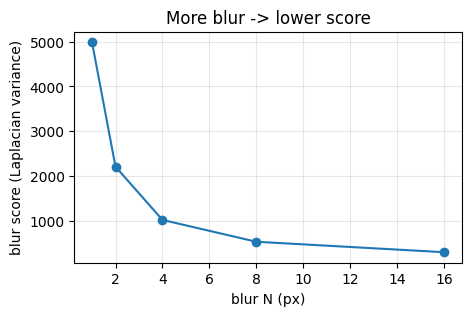

Test 3 passed


In [8]:
Ns = [1, 2, 4, 8, 16]
scores = [blur_score(motion_blur(img, N)) for N in Ns]
for N, s in zip(Ns, scores):
    print(f"N = {N:2d} px  ->  score = {s:8.1f}")
assert all(a > b for a, b in zip(scores, scores[1:])), "score should drop as N grows"

plt.figure(figsize=(5, 3))
plt.plot(Ns, scores, "o-")
plt.xlabel("blur N (px)"); plt.ylabel("blur score (Laplacian variance)")
plt.title("More blur -> lower score"); plt.grid(alpha=.3)
plt.show()
print("Test 3 passed")

### Demo 1: a fake flight with vibration bursts (we know the true blur)

We don't have drone footage yet, so we fake one: a camera window **slides across the photo** (the drone flying), each frame gets a little motion blur, and some frames get a **vibration burst** (big N). Because we chose N ourselves, we can check that the score finds exactly the bad frames.

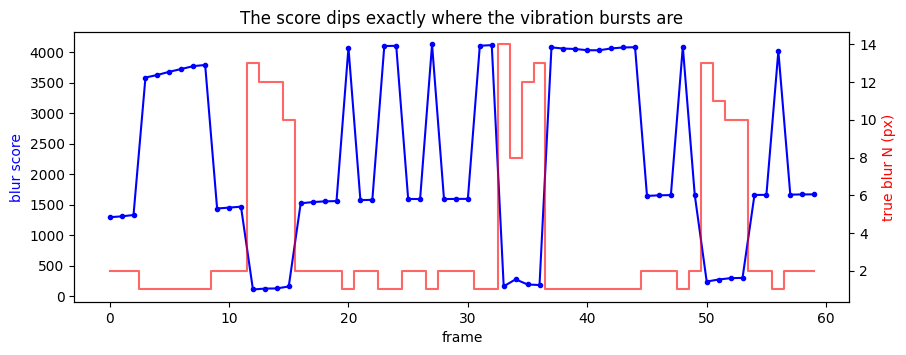

correlation between score and true blur: -0.74  (close to -1 = the score tracks blur well)


In [9]:
rng = np.random.default_rng(0)
n_frames, win_w, win_h = 60, 320, 240
xs = np.linspace(0, img.shape[1] - win_w, n_frames).astype(int)   # window moves left -> right
true_N = rng.integers(1, 3, n_frames)                             # normal flight: 1-2 px of blur
for start in (12, 33, 50):                                        # three vibration bursts
    true_N[start:start + 4] = rng.integers(8, 15, 4)

frames = [motion_blur(img[0:win_h, x:x + win_w], int(N)) for x, N in zip(xs, true_N)]
fake_scores = np.array([blur_score(f) for f in frames])

fig, ax1 = plt.subplots(figsize=(10, 3.5))
ax1.plot(fake_scores, "b.-", label="blur score")
ax1.set_xlabel("frame"); ax1.set_ylabel("blur score", color="b")
ax2 = ax1.twinx()
ax2.step(range(n_frames), true_N, "r", where="mid", alpha=.6, label="true blur N")
ax2.set_ylabel("true blur N (px)", color="r")
plt.title("The score dips exactly where the vibration bursts are"); plt.show()

corr = np.corrcoef(fake_scores, true_N)[0, 1]
print(f"correlation between score and true blur: {corr:.2f}  (close to -1 = the score tracks blur well)")

### Picking the sharpest frames

A drone camera gives 25 frames per second, far more than we need. So in every short window of frames (here 5 frames = 0.2 s), keep only the **sharpest** one and send that one to YOLO. Vibration frames get skipped automatically.

kept frames: [4, 8, 11, 19, 24, 27, 32, 37, 44, 48, 54, 56]
average true blur, all frames : 3.5 px
average true blur, kept frames: 1.2 px


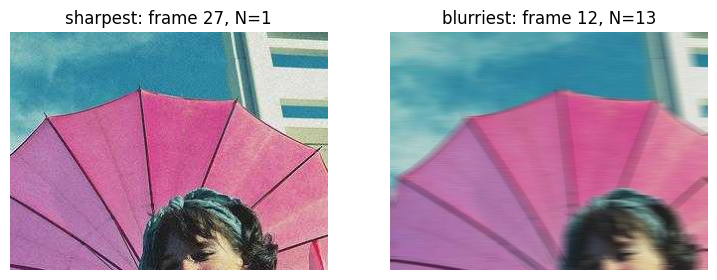

In [10]:
def pick_sharpest(scores, window=5):
    """Index of the sharpest frame in each window of `window` consecutive frames."""
    scores = np.asarray(scores)
    return [start + int(np.argmax(scores[start:start + window]))     # best frame inside this window
            for start in range(0, len(scores), window)]

keep = pick_sharpest(fake_scores, window=5)
print("kept frames:", keep)
print(f"average true blur, all frames : {true_N.mean():.1f} px")
print(f"average true blur, kept frames: {true_N[keep].mean():.1f} px")

worst, best = int(np.argmin(fake_scores)), int(np.argmax(fake_scores))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].imshow(cv.cvtColor(frames[best], cv.COLOR_BGR2RGB));  ax[0].set_title(f"sharpest: frame {best}, N={true_N[best]}")
ax[1].imshow(cv.cvtColor(frames[worst], cv.COLOR_BGR2RGB)); ax[1].set_title(f"blurriest: frame {worst}, N={true_N[worst]}")
for a in ax: a.axis("off")
plt.show()

### Demo 2: a real video

Swap `VIDEO_PATH` for drone footage when the team has some. For now it's the Session 2 clip.

159 frames, score from 92 to 165


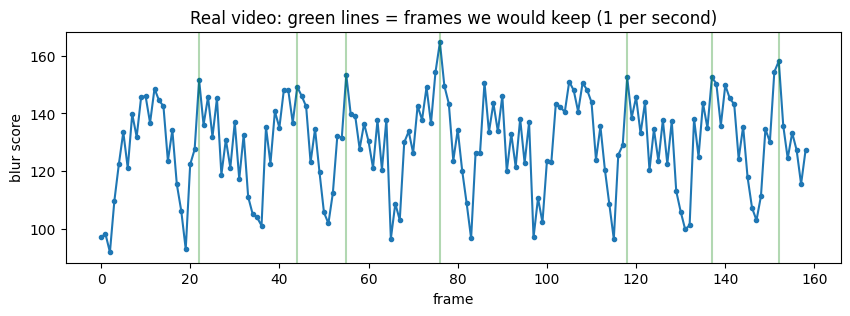

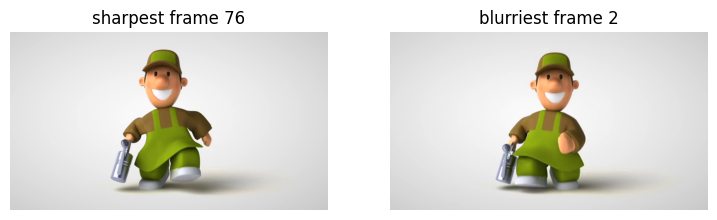

In [11]:
VIDEO_PATH = "../../phase 1 of the season/Session2/Videos/video1.mp4"

cap = cv.VideoCapture(VIDEO_PATH)
vid_frames = []
while True:
    ok, frame = cap.read()     # read one frame at a time until the video ends
    if not ok:
        break
    vid_frames.append(frame)
cap.release()
assert vid_frames, "no frames read, check VIDEO_PATH"

vid_scores = np.array([blur_score(f) for f in vid_frames])
print(f"{len(vid_frames)} frames, score from {vid_scores.min():.0f} to {vid_scores.max():.0f}")

plt.figure(figsize=(10, 3))
plt.plot(vid_scores, ".-")
for k in pick_sharpest(vid_scores, window=25):    # the sharpest frame in each second (25 fps)
    plt.axvline(k, color="g", alpha=.3)
plt.xlabel("frame"); plt.ylabel("blur score"); plt.title("Real video: green lines = frames we would keep (1 per second)")
plt.show()

w, b = int(np.argmin(vid_scores)), int(np.argmax(vid_scores))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].imshow(cv.cvtColor(vid_frames[b], cv.COLOR_BGR2RGB)); ax[0].set_title(f"sharpest frame {b}")
ax[1].imshow(cv.cvtColor(vid_frames[w], cv.COLOR_BGR2RGB)); ax[1].set_title(f"blurriest frame {w}")
for a in ax: a.axis("off")
plt.show()

### M3 result ✅ done

- **Test 3 passed:** the score drops every time N grows.
- **Fake flight:** the score dips exactly at the vibration bursts, and keeping the sharpest frame per window cuts the average blur.
- **Real video:** the same code scores every frame and picks one sharp frame per second.

**Limits to say in the talk:**
- The score depends on **what's in the picture**: a busy field has more edges than a plain sky. So compare scores **within the same flight/scene**, not across different scenes.
- **Noise** (high ISO) also makes tiny "edges", so a noisy frame can score high without being sharp.
- It says *how blurry*, not *which direction* the blur goes.

Next: **M4**, does blur actually hurt YOLO? Recall vs blur on VisDrone.

## M4: Does blur hurt YOLO? Recall vs blur on VisDrone

**Where it fits:** M1 predicted blur, M2 creates it, M3 detects it. M4 answers the main question: **how much blur can YOLO handle before it starts missing objects, especially small ones?**

**The experiment:**
1. Take real drone photos (VisDrone val set) and run a pretrained YOLO (no training) on the **sharp** photo. Those boxes are the **answer key**.
2. Blur the same photo by N px with the M2 function and run YOLO again.
3. For every box on the answer key: is there still a box of the **same class** that overlaps it by at least half (**IoU ≥ 0.5**)? Found / total = **recall**.
4. Do it for N = 2, 4, 8, 12, 16 and split the objects into **small** (area < 32×32 px) and **big**.

**Why the answer key is YOLO's own sharp result:** VisDrone's labels ("pedestrian", "van") don't match YOLO's COCO classes ("person", "car"). Comparing YOLO with itself, sharp vs blurred, measures *only* what blur took away.

In [12]:
from pathlib import Path
from ultralytics import YOLO

MODEL_PATH = "../../phase 1 of the season/tasks/yolov8n.pt"      # pretrained on COCO, no training
VIS_DIR    = Path("datasets/VisDrone2019-DET-val/images")
N_IMAGES   = 150      # a sample of the 548 photos, enough for a stable curve on a CPU
IMGSZ      = 1280     # bigger input size so YOLO can still see tiny objects
CONF       = 0.25     # minimum confidence for a box to count
BLUR_NS    = [2, 4, 8, 12, 16]
SMALL_AREA = 32 * 32  # "small object" = area under 32x32 px (the COCO definition)

model = YOLO(MODEL_PATH)
paths = sorted(VIS_DIR.glob("*.jpg"))[:N_IMAGES]
print(f"{len(paths)} images, example size: {cv.imread(str(paths[0])).shape}")

150 images, example size: (1080, 1920, 3)


In [13]:
def detect(img):
    """Run YOLO on one image -> (boxes [x1,y1,x2,y2], class ids)."""
    r = model.predict(img, imgsz=IMGSZ, conf=CONF, verbose=False)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int)

def iou(box, boxes):
    """Overlap between one box and many boxes: intersection area / union area (0 = no overlap, 1 = identical)."""
    x1 = np.maximum(box[0], boxes[:, 0]); y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2]); y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda b: (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])
    return inter / (area(box) + area(boxes) - inter + 1e-9)

def found_again(ref_boxes, ref_cls, new_boxes, new_cls, thr=0.5):
    """For each answer-key box: True if a new box of the same class overlaps it with IoU >= thr.
    Each new box can only be used once (so one box can't 'find' two objects)."""
    used = np.zeros(len(new_boxes), bool)
    hits = np.zeros(len(ref_boxes), bool)
    for i, (b, c) in enumerate(zip(ref_boxes, ref_cls)):
        if len(new_boxes) == 0:
            break
        scores = iou(b, new_boxes)
        scores[(new_cls != c) | used] = 0           # other classes or already-used boxes don't count
        j = int(np.argmax(scores))
        if scores[j] >= thr:
            hits[i], used[j] = True, True
    return hits

### Run the experiment

For each photo: detect on the sharp photo (answer key), then blur at every N and check which answer-key objects survive. This takes a few minutes on a CPU.

In [14]:
import time
rows = []          # one row per answer-key object per blur level
t0 = time.time()
for k, p in enumerate(paths):
    img_vd = cv.imread(str(p))
    ref_boxes, ref_cls = detect(img_vd)                        # the answer key
    if len(ref_boxes) == 0:
        continue
    areas = (ref_boxes[:, 2] - ref_boxes[:, 0]) * (ref_boxes[:, 3] - ref_boxes[:, 1])
    for N in BLUR_NS:
        new_boxes, new_cls = detect(motion_blur(img_vd, N))    # same photo, N px of motion blur
        hits = found_again(ref_boxes, ref_cls, new_boxes, new_cls)
        rows += [(p.name, N, a < SMALL_AREA, h) for a, h in zip(areas, hits)]
    if k % 10 == 0:
        print(f"image {k + 1}/{len(paths)}  ({time.time() - t0:.0f} s)")

import pandas as pd
res = pd.DataFrame(rows, columns=["image", "N", "small", "found"])
n_ref = res[res.N == BLUR_NS[0]]
print(f"answer key: {len(n_ref)} objects ({n_ref.small.sum()} small, {(~n_ref.small).sum()} big)")

image 1/150  (15 s)
image 11/150  (35 s)
image 21/150  (54 s)
image 31/150  (75 s)
image 41/150  (95 s)
image 51/150  (117 s)
image 61/150  (139 s)
image 71/150  (163 s)
image 81/150  (182 s)
image 91/150  (194 s)
image 101/150  (218 s)
image 111/150  (243 s)
image 121/150  (266 s)
image 131/150  (292 s)
image 141/150  (318 s)
answer key: 3301 objects (1496 small, 1805 big)


    all recall %  small recall %  big recall %
N                                             
0          100.0           100.0         100.0
2           91.3            87.4          94.6
4           74.9            61.9          85.7
8           46.7            26.8          63.3
12          28.4            11.6          42.4
16          18.8             5.1          30.0


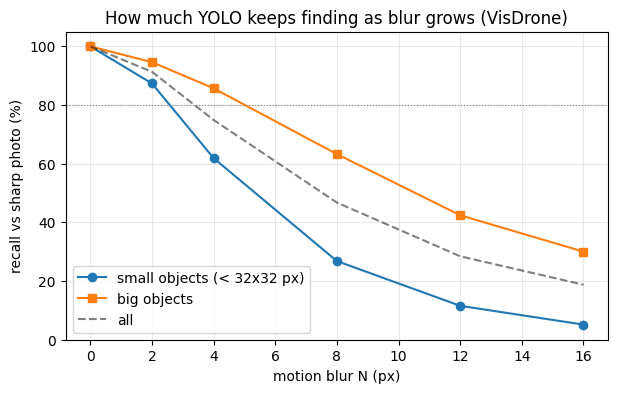

In [15]:
summary = pd.DataFrame({
    "all":   res.groupby("N").found.mean(),
    "small": res[res.small].groupby("N").found.mean(),
    "big":   res[~res.small].groupby("N").found.mean(),
})
summary.loc[0] = 1.0              # N = 0 is the sharp photo itself: recall 100% by definition
summary = summary.sort_index()
print((summary * 100).round(1).rename(columns=lambda c: c + " recall %"))

plt.figure(figsize=(7, 4))
plt.plot(summary.index, summary["small"] * 100, "o-", label="small objects (< 32x32 px)")
plt.plot(summary.index, summary["big"] * 100, "s-", label="big objects")
plt.plot(summary.index, summary["all"] * 100, "k--", alpha=.5, label="all")
plt.axhline(80, color="gray", lw=.8, ls=":")
plt.xlabel("motion blur N (px)"); plt.ylabel("recall vs sharp photo (%)")
plt.title("How much YOLO keeps finding as blur grows (VisDrone)")
plt.ylim(0, 105); plt.grid(alpha=.3); plt.legend()
plt.show()

### See it on one photo

Green = found on the sharp photo. On the blurred photo, the same boxes are drawn green if YOLO still found them and red if it lost them.

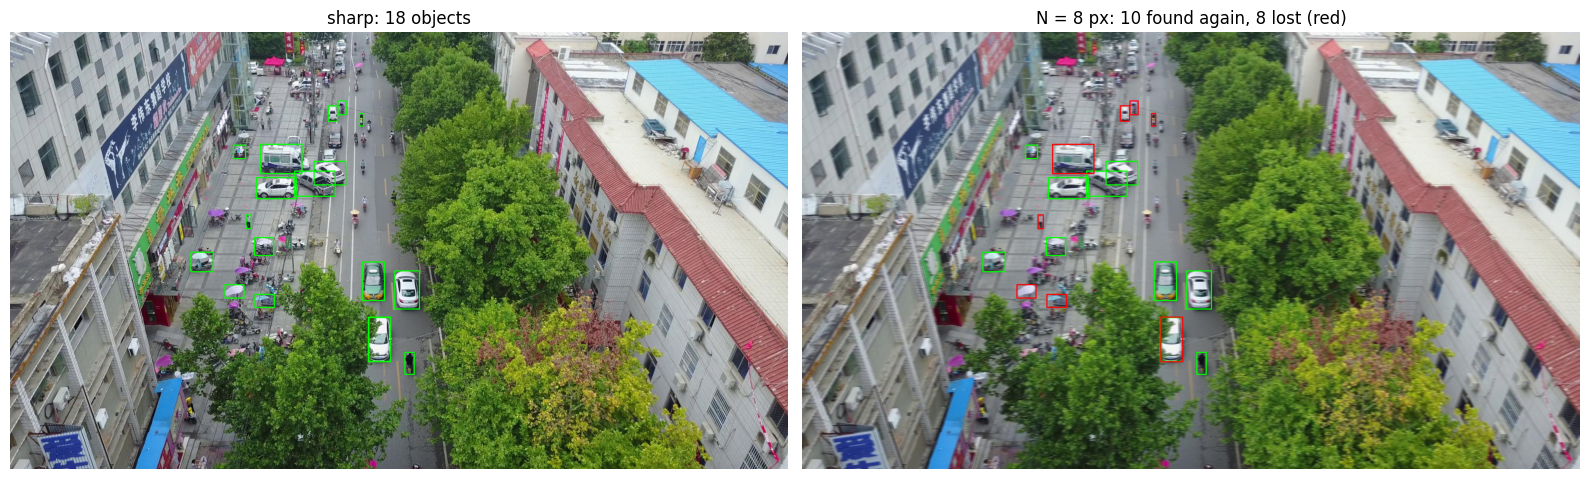

In [16]:
SHOW_N = 8
p = paths[0]
img_vd = cv.imread(str(p))
ref_boxes, ref_cls = detect(img_vd)
blurred = motion_blur(img_vd, SHOW_N)
hits = found_again(ref_boxes, ref_cls, *detect(blurred))

left, right = img_vd.copy(), blurred.copy()
for b, h in zip(ref_boxes.astype(int), hits):
    cv.rectangle(left, tuple(b[:2]), tuple(b[2:]), (0, 255, 0), 2)
    cv.rectangle(right, tuple(b[:2]), tuple(b[2:]), (0, 255, 0) if h else (0, 0, 255), 2)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].imshow(cv.cvtColor(left, cv.COLOR_BGR2RGB));  ax[0].set_title(f"sharp: {len(ref_boxes)} objects")
ax[1].imshow(cv.cvtColor(right, cv.COLOR_BGR2RGB)); ax[1].set_title(f"N = {SHOW_N} px: {hits.sum()} found again, {(~hits).sum()} lost (red)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### From "px" back to flying rules (closing the loop with M1)

Find the largest blur where small-object recall stays at or above a target (80%), then use the M1 formula backwards:

`max shutter time = max blur (px) × GSD ÷ speed`

In [17]:
TARGET = 0.80
ok = summary.index[summary["small"] >= TARGET]
max_px = int(ok.max())
print(f"small-object recall stays >= {TARGET:.0%} up to N = {max_px} px of blur\n")

speed = 20.0                                      # m/s, fixed wing
for name, gsd in [("brief's camera (4.7 cm/px at 75 m)", 0.047), ("A8 mini 1080p (7.2 cm/px at 75 m)", 0.072)]:
    t = max_px * gsd / speed if max_px > 0 else float("nan")
    print(f"{name}: shutter must be faster than 1/{1 / t:.0f} s  (at {speed:.0f} m/s, 75 m)")

small-object recall stays >= 80% up to N = 2 px of blur

brief's camera (4.7 cm/px at 75 m): shutter must be faster than 1/213 s  (at 20 m/s, 75 m)
A8 mini 1080p (7.2 cm/px at 75 m): shutter must be faster than 1/139 s  (at 20 m/s, 75 m)


### M4 result ✅ done

150 VisDrone photos, 3301 objects on the answer key (1496 small, 1805 big):

| blur N (px) | all | small (< 32×32 px) | big |
|---|---|---|---|
| 0 | 100% | 100% | 100% |
| 2 | 91.3% | 87.4% | 94.6% |
| 4 | 74.9% | **61.9%** | 85.7% |
| 8 | 46.7% | 26.8% | 63.3% |
| 12 | 28.4% | 11.6% | 42.4% |
| 16 | 18.8% | 5.1% | 30.0% |

**What it means:**
- Blur hurts **small objects much faster** than big ones: at 4 px, small objects already lose ~38% while big ones lose ~14%.
- Our flag (2 × 1 m) at 75 m is about 43 × 21 px (brief's camera) or 28 × 14 px (A8 mini), so it's a **small object**: the small curve is the one that matters for us.
- Small-object recall stays above 80% only up to about **2 px** of blur (it's already 62% at 4 px).

**Back to flying rules (M1 formula backwards), at 20 m/s and 75 m, keeping blur ≤ 2 px:**
- brief's camera (4.7 cm/px): shutter faster than **1/213 s**
- A8 mini 1080p (7.2 cm/px): shutter faster than **1/139 s**
- To keep it ≤ 1 px (safer), double those: about 1/425 s and 1/280 s.

**Limits to say in the talk:**
- The answer key is YOLO's own sharp detections, not human labels, so this measures **what blur takes away**, not YOLO's absolute accuracy.
- VisDrone objects are people and cars, not flags; a model trained on flags may react a bit differently.
- Synthetic blur is a perfect straight line; real blur also has vibration wobble, rolling-shutter bending and noise.
- We tested only N = 2, 4, 8…, so the true 80% point is somewhere between 2 and 4 px.

Next: **M5** (reading: augmentation and deblurring) and **M6** (one-page summary + talk).

## M5: Fixes, can we get the lost objects back?

**Where it fits:** M4 showed blur kills small objects (62% recall at 4 px, 27% at 8 px). M5 tests the fixes.

There are three families of fixes:

| Fix | When | Idea | Tested here? |
|---|---|---|---|
| **Camera settings** (faster shutter) | before the flight | less blur in the first place (the M1 + M4 recommendation) | already done in M4 |
| **Sharpest-frame selection** | during the flight | skip the vibration frames (M3) | already done in M3 |
| **Deblurring** | after capture, before YOLO | undo the blur mathematically | ✅ **Wiener filter, below** |
| **Blur augmentation** | when training YOLO | show YOLO blurred examples so it gets used to blur | ✅ **the generator, below** (no training: the task says no training) |

**Deep deblurring** (DeblurGAN-v2, NAFNet) learns to remove *unknown* blur, but needs big models and a GPU, too heavy for the drone's computer. Our blur is **known** from M1 (speed, shutter, height → N, and the flight direction → the angle), so a classic filter that *uses* the known PSF is a good fit.

### Fix 1: Wiener deconvolution (undo a known blur)

**The idea:** blurring = convolution with the PSF. In the frequency domain (Fourier), convolution becomes a simple **multiplication**: `blurred = sharp × H` (H = the PSF in frequency). So to undo it we'd *divide* by H.

**The catch:** H is almost 0 at some frequencies (the fine details the blur wiped out). Dividing by ~0 explodes any tiny noise. Wiener fixes that with a safety term **K**:

```
sharp ≈ blurred × conj(H) / (|H|² + K)
```

- where H is big (the blur didn't hurt that detail): ≈ divide by H, so the detail comes back
- where H ≈ 0 (the detail is gone): ≈ 0 instead of exploding noise
- bigger K = safer against noise but less sharp

In [18]:
def wiener_deblur(img, N, K=0.002):
    """Undo a horizontal motion blur of N px, knowing its PSF (Wiener deconvolution)."""
    h, w = img.shape[:2]
    psf = np.zeros((h, w), np.float32)
    psf[0, :N] = 1.0 / N                          # the same PSF as make_motion_kernel(N), placed in an image-sized grid
    psf = np.roll(psf, -(N // 2), axis=1)         # centre it on pixel (0, 0), the way filter2D centres the kernel
    H = np.fft.fft2(psf)                          # the PSF in the frequency domain
    G = np.conj(H) / (np.abs(H) ** 2 + K)         # Wiener: "divide by H", but safely where H is ~0
    out = np.empty(img.shape, np.float32)
    for c in range(img.shape[2]):                 # each colour channel separately
        out[..., c] = np.real(np.fft.ifft2(np.fft.fft2(img[..., c].astype(np.float32)) * G))
    return np.clip(out, 0, 255).astype(np.uint8)  # back to a normal 0-255 image

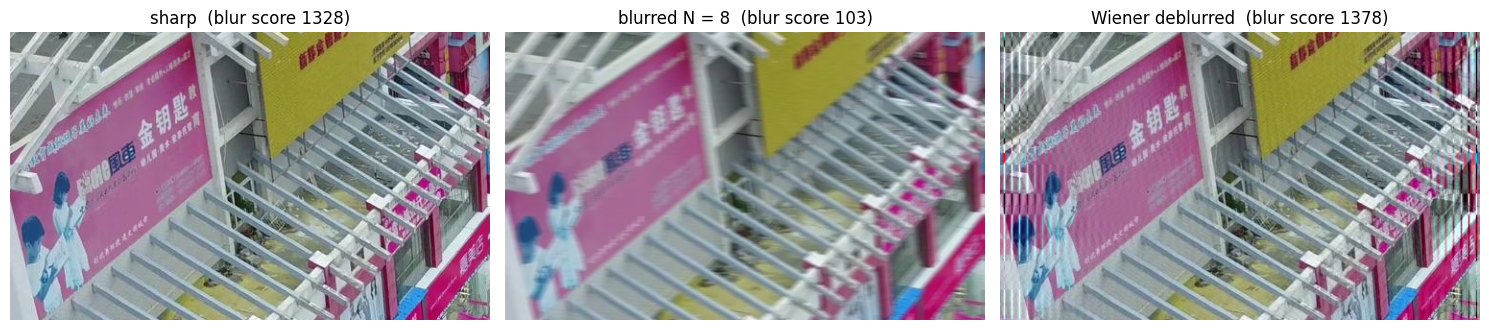

In [19]:
# See it: a crop of a VisDrone photo, sharp -> blurred 8 px -> deblurred
p = paths[3]
crop = cv.imread(str(p))[200:500, 300:800]
blurred8 = motion_blur(crop, 8)
fixed8 = wiener_deblur(blurred8, 8)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, im, t in zip(ax, [crop, blurred8, fixed8], ["sharp", "blurred N = 8", "Wiener deblurred"]):
    a.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB)); a.set_title(f"{t}  (blur score {blur_score(im):.0f})"); a.axis("off")
plt.tight_layout(); plt.show()

### Does deblurring bring YOLO's recall back?

Same answer-key method as M4, on 50 photos, comparing three versions of each photo: **blurred**, **deblurred (ideal)**, and two **realistic** cases:

- **ideal:** we know N exactly and there's no camera noise (best case)
- **+ noise:** a little sensor noise (σ = 2, like a normal ISO) added after the blur, as a real camera would
- **wrong N:** the true blur is 8 px but we guess 6 px (speed or height estimate slightly off)

In [20]:
rng = np.random.default_rng(1)
def add_noise(img, sigma=2.0):
    """Gaussian sensor noise, like a real camera adds."""
    return np.clip(img + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)

N_FIX = 50
conds = {  # name -> function(blurred image, true N) -> image given to YOLO
    "blurred (no fix)":   lambda b, N: b,
    "deblurred, ideal":   lambda b, N: wiener_deblur(b, N),
    "deblurred, + noise": lambda b, N: wiener_deblur(add_noise(b), N, K=0.01),
    "deblurred, wrong N": lambda b, N: wiener_deblur(b, max(N - 2, 1)),
}
fix_rows = []
for p in paths[:N_FIX]:
    im = cv.imread(str(p))
    ref_boxes, ref_cls = detect(im)                                   # answer key from the sharp photo
    if len(ref_boxes) == 0:
        continue
    small = (ref_boxes[:, 2] - ref_boxes[:, 0]) * (ref_boxes[:, 3] - ref_boxes[:, 1]) < SMALL_AREA
    for N in [4, 8]:
        b = motion_blur(im, N)
        for name, f in conds.items():
            h = found_again(ref_boxes, ref_cls, *detect(f(b, N)))
            fix_rows += [(N, name, s, x) for s, x in zip(small, h)]

fix = pd.DataFrame(fix_rows, columns=["N", "condition", "small", "found"])
table = (fix.groupby(["N", "condition", "small"]).found.mean().unstack() * 100).round(1)
table.columns = ["big recall %", "small recall %"]
print(table[["small recall %", "big recall %"]])

                      small recall %  big recall %
N condition                                       
4 blurred (no fix)              63.0          89.3
  deblurred, + noise            71.2          85.5
  deblurred, ideal              82.6          89.4
  deblurred, wrong N            64.7          90.2
8 blurred (no fix)              25.6          70.2
  deblurred, + noise            48.4          72.5
  deblurred, ideal              72.6          84.4
  deblurred, wrong N            18.5          48.0


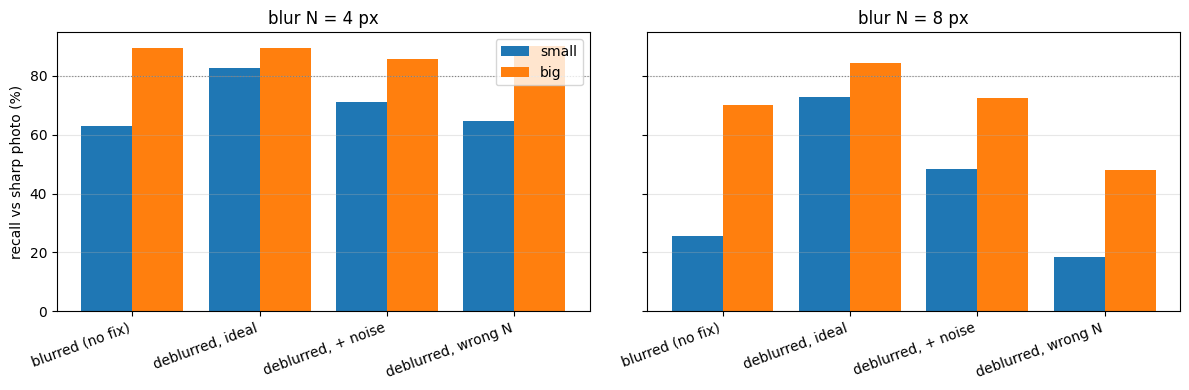

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, N in zip(ax, [4, 8]):
    t = table.loc[N].reindex(list(conds))
    x = np.arange(len(t))
    a.bar(x - .2, t["small recall %"], .4, label="small")
    a.bar(x + .2, t["big recall %"], .4, label="big")
    a.set_xticks(x); a.set_xticklabels(t.index, rotation=20, ha="right")
    a.set_title(f"blur N = {N} px"); a.axhline(80, color="gray", ls=":", lw=.8); a.grid(axis="y", alpha=.3)
ax[0].set_ylabel("recall vs sharp photo (%)"); ax[0].legend()
plt.tight_layout(); plt.show()

### Fix 2: blur augmentation (for when the team trains its flag detector)

If the team trains its own YOLO on flag photos, they can add **random motion blur** to the training images, so the model learns that a smeared flag is still a flag. Real blur isn't always perfectly horizontal (turns, wind, vibration), so the generator also picks a random **angle**. This extends the M2 kernel from a row to a line at any angle.

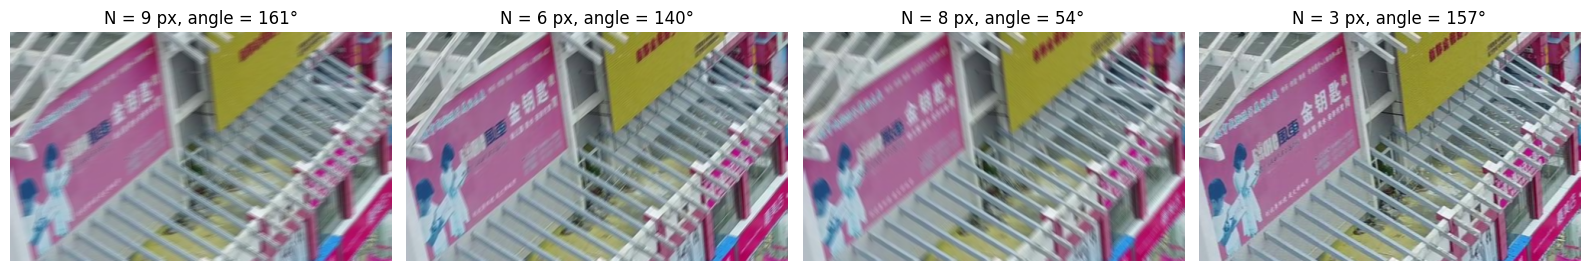

In [22]:
def angled_motion_kernel(N, angle_deg):
    """N x N kernel with a line of length N at the given angle, weights sum to 1."""
    k = np.zeros((N, N), np.float32)
    c = (N - 1) / 2
    dx, dy = np.cos(np.radians(angle_deg)) * c, np.sin(np.radians(angle_deg)) * c
    cv.line(k, (int(round(c - dx)), int(round(c - dy))), (int(round(c + dx)), int(round(c + dy))), 1.0, 1)  # draw the line
    return k / k.sum()                                          # normalise: sum = 1, brightness kept

def random_blur_augment(img, rng, max_N=9):
    """Training-time augmentation: random blur length (0..max_N px) and random direction."""
    N = int(rng.integers(1, max_N + 1))
    if N == 1:
        return img, 1, 0                                         # sometimes leave it sharp
    angle = float(rng.uniform(0, 180))
    return cv.filter2D(img, -1, angled_motion_kernel(N, angle)), N, angle

aug_rng = np.random.default_rng(7)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a in ax:
    out, N, ang = random_blur_augment(crop, aug_rng)
    a.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB)); a.set_title(f"N = {N} px, angle = {ang:.0f}°"); a.axis("off")
plt.tight_layout(); plt.show()

# with Ultralytics this is a one-line idea: apply random_blur_augment to the training images,
# or use albumentations.MotionBlur, which does the same thing during training

### M5 result ✅ done

Recall vs the sharp photo (50 VisDrone photos):

| blur | condition | small | big |
|---|---|---|---|
| 4 px | blurred (no fix) | 63.0% | 89.3% |
| 4 px | deblurred, ideal | **82.6%** | 89.4% |
| 4 px | deblurred, + noise | 71.2% | 85.5% |
| 4 px | deblurred, wrong N (guessed 2) | 64.7% | 90.2% |
| 8 px | blurred (no fix) | 25.6% | 70.2% |
| 8 px | deblurred, ideal | **72.6%** | 84.4% |
| 8 px | deblurred, + noise | 48.4% | 72.5% |
| 8 px | deblurred, wrong N (guessed 6) | **18.5%** | 48.0% |

**What it means:**
- In the **ideal** case, Wiener deblurring brings back most of the small objects (8 px: 26% → 73%).
- **Noise** cuts that gain roughly in half (8 px: 26% → 48%), still a clear win.
- A **wrong guess of N** makes it useless at 4 px and **worse than doing nothing** at 8 px (26% → 19%), because the filter "undoes" a blur that isn't there and adds ringing.

**Recommendation:** deblurring is a **bonus, not the main fix**. It only helps if N is estimated accurately (speed from the flight controller, height, shutter, and the flight direction for the angle). The main fixes stay: **a fast enough shutter** (M4: ≤ 2 px) and **sharpest-frame selection** (M3). If the team trains its own flag detector, add **blur augmentation** (the generator above), which costs nothing at flight time.

Next: **M6**, the one-page summary and the 10-minute talk.